<img src="http://imgur.com/1ZcRyrc.png" style="float: left; margin: 20px; height: 55px">

# Introduction to Gridsearching Hyperparameters

_Authors: Kiefer Katovich (SF), David Yerrington (SF)_

---

![](https://snag.gy/aYcCt2.jpg)

### Learning Objective
- Describe what the terms gridsearch and hyperparameter mean.
- Build a gridsearching procedure from scratch.
- Apply sklearn's `GridSearchCV` object with basketball data to optimize a KNN model.
- Use and evaluate attributes of the gridsearch object.
- Describe the pitfalls of searching large hyperparameter spaces.

### Lesson Guide
- [What is "grid searching"? What are "hyperparameters"?](#intro)
- [Basketball Data](#basketball-data)
- [Fitting a Default KNN](#fit-knn)
- [Searching for the Best Hyperparameters](#searching)
    - [Grid Search Pseudocode](#pseudocode)
    - [Using `GridSearchCV`](#gscv)
- [A Caution on Grid Searching](#caution)
- [Independent Practice: Grid Searching Regularization Penalties with Logistic Regression](#practice)

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use('fivethirtyeight')

%matplotlib inline

<a id='intro'></a>

## What is "grid searching"? What are "hyperparameters"?

---

Models often have built-in quantities that we can use to fine-tune our results. For example, when we choose a linear regression, we may decide to add a penalty to the loss function such as the Ridge or the Lasso. The Ridge and Lasso have a hyperparameter $\alpha$, which we specify ourselves.

> **Parameters** are quantities that a model can learn (for example, coefficients of linear regression).

> **Hyperparameters** are quantities that a model cannot learn, that we must decide on ourselves (for example, the penalty term $\alpha$).

Models often have **multiple hyperparameters**. For example, in a kNN model, we have $k$, the number of neighbors to use, but we also have other chocies such as _weights_ or _distance metric_ (usually these are set to "uniform" and "Euclidean", but they can be changed!).

However, different values for hyperparameters result in different quality fits. **We want to find the optimal values for our hyper parameters.**

![](../imgs/grid.jpg)

**One method of searching for the optimal set of hyperparameters is called gridsearching.**

Gridsearching gets its name from the fact that we are searching over a "grid" of parameters. For example, imagine the `n_neighbors` hyperparameters on the x-axis and `weights` on the y-axis, and we need to test all points on the grid.

**Gridsearching uses cross-validation internally to evaluate the performance of each set of hyperparameters.** More on this later.

<a id='basketball-data'></a>

<a id='basketball-data'></a>

## Basketball Data

---

To explore the process of gridsearching over sets of hyperparameters, we will use some basketball data. The data below has statistics for 4 different seasons of NBA basketball: 2013-2016.
- This data includes aggregate statistical data for each game. 
- The data of each game is aggregated by match for all players.
- Scraped from http://www.basketball-reference.com

Many of the columns in the dataset represent the mean of a statistic across the last 10 games, for example. Non-target statistics are for *prior* games, they do not include information about player performance in the current game.

**We are interested in predicting whether the home team will win the game or not.** This is a classification problem.


### Load the data and create the target and predictor matrix
- The target will be a binary column of whether the home team wins.
- The predictors should be numeric statistics columns.

Exclude these columns from the predictor matrix:

    ['GameId','GameDate','GameTime','HostName',
     'GuestName','total_score','total_line','game_line',
     'winner','loser','host_wins','Season']


In [2]:
data = pd.read_csv('../datasets/basketball_data.csv')

In [3]:
data.head()

,Season,GameId,GameDate,GameTime,HostName,GuestName,total_score,total_line,game_line,Host_HostRank,...,gPTS_avg10,gTS%_avg10,g3PAR_avg10,gFTr_avg10,gDRB%_avg10,gTRB%_avg10,gAST%_avg10,gSTL%_avg10,gBLK%_avg10,gDRtg_avg10
0,2013,201212090LAL,2012-12-09,6:30 pm,Los Angeles Lakers,Utah Jazz,227.0,207.5,7.5,13,...,99.0,0.5206,0.2230,0.2981,69.22,50.05,61.57,8.63,10.31,110.87
1,2013,201212100PHI,2012-12-10,7:00 pm,Philadelphia 76ers,Detroit Pistons,201.0,186.5,5.5,13,...,90.3,0.5077,0.2144,0.3095,71.46,49.48,59.83,6.48,9.46,107.91
2,2013,201212100HOU,2012-12-10,7:00 pm,Houston Rockets,San Antonio Spurs,240.0,212.0,-7.0,12,...,108.0,0.5915,0.2743,0.2518,74.26,50.99,61.82,8.30,6.85,101.41
3,2013,201212110BRK,2012-12-11,7:00 pm,Brooklyn Nets,New York Knicks,197.0,195.5,-3.5,12,...,100.3,0.5473,0.3595,0.2544,74.23,47.88,52.07,9.31,7.64,109.24
4,2013,201212110DET,2012-12-11,7:30 pm,Detroit Pistons,Denver Nuggets,195.0,203.5,-4.5,11,...,101.1,0.5605,0.2173,0.3177,68.45,50.40,56.33,7.67,7.83,114.86


In [4]:
data.columns

Index(['Season', 'GameId', 'GameDate', 'GameTime', 'HostName', 'GuestName',
       'total_score', 'total_line', 'game_line', 'Host_HostRank',
       'Host_GameRank', 'Guest_GuestRank', 'Guest_GameRank', 'host_win_count',
       'host_lose_count', 'guest_win_count', 'guest_lose_count', 'game_behind',
       'winner', 'loser', 'host_place_streak', 'guest_place_streak',
       'hq1_avg10', 'hq2_avg10', 'hq3_avg10', 'hq4_avg10', 'hPace_avg10',
       'heFG%_avg10', 'hTOV%_avg10', 'hORB%_avg10', 'hFT/FGA_avg10',
       'hORtg_avg10', 'hFG_avg10', 'hFGA_avg10', 'hFG%_avg10', 'h3P_avg10',
       'h3PA_avg10', 'h3P%_avg10', 'hFT_avg10', 'hFTA_avg10', 'hFT%_avg10',
       'hORB_avg10', 'hDRB_avg10', 'hTRB_avg10', 'hAST_avg10', 'hSTL_avg10',
       'hBLK_avg10', 'hTOV_avg10', 'hPF_avg10', 'hPTS_avg10', 'hTS%_avg10',
       'h3PAR_avg10', 'hFTr_avg10', 'hDRB%_avg10', 'hTRB%_avg10',
       'hAST%_avg10', 'hSTL%_avg10', 'hBLK%_avg10', 'hDRtg_avg10', 'gq1_avg10',
       'gq2_avg10', 'gq3_avg10', 'gq

In [5]:
data.shape

(3768, 96)

In [6]:
data.Season.unique()

array([2013, 2014, 2015, 2016])

In [7]:
data.winner.head()

0             Utah Jazz
1    Philadelphia 76ers
2     San Antonio Spurs
3       New York Knicks
4        Denver Nuggets
Name: winner, dtype: object

In [8]:
# Create a binary int column to represent host's win/loss
data['host_wins'] = (data.HostName == data.winner).astype(int)

In [9]:
X = data.drop(['GameId','GameDate','GameTime','HostName',
               'GuestName','total_score','total_line', 'game_line',
               'winner','loser','host_wins','Season'], axis=1)
y = data.host_wins

In [10]:
X.shape

(3768, 85)

### Create the training and testing data
- Test data should be the 2016 season data, train data will be the previous seasons.
- Make sure to standardize your predictor matrix (easiest to do prior to splitting the data into training and testing)!

In [11]:
from sklearn.preprocessing import StandardScaler

In [12]:
sc = StandardScaler()
X_sc = sc.fit_transform(X)

/home/tim/.local/lib/python3.6/site-packages/sklearn/preprocessing/data.py:625: DataConversionWarning: Data with input dtype int64, float64 were all converted to float64 by StandardScaler.
  return self.partial_fit(X, y)
/home/tim/.local/lib/python3.6/site-packages/sklearn/base.py:462: DataConversionWarning: Data with input dtype int64, float64 were all converted to float64 by StandardScaler.
  return self.fit(X, **fit_params).transform(X)


In [13]:
X_train = X[data.Season.isin([2013, 2014, 2015])]
X_test = X[data.Season == 2016]

y_train = y[data['Season'].isin([2013, 2014, 2015])]
y_test = y[data['Season'] == 2016]

In [14]:
sc = StandardScaler()
X_sc_train = sc.fit_transform(X_train)
X_sc_test = sc.transform(X_test)

/home/tim/.local/lib/python3.6/site-packages/sklearn/preprocessing/data.py:625: DataConversionWarning: Data with input dtype int64, float64 were all converted to float64 by StandardScaler.
  return self.partial_fit(X, y)
/home/tim/.local/lib/python3.6/site-packages/sklearn/base.py:462: DataConversionWarning: Data with input dtype int64, float64 were all converted to float64 by StandardScaler.
  return self.fit(X, **fit_params).transform(X)
/home/tim/.local/lib/python3.6/site-packages/ipykernel_launcher.py:3: DataConversionWarning: Data with input dtype int64, float64 were all converted to float64 by StandardScaler.
  This is separate from the ipykernel package so we can avoid doing imports until


In [15]:
X_train.shape

(2783, 85)

In [16]:
X_test.shape

(985, 85)

<a id='fit-knn'></a>

## Fitting the Default KNN

---

Below we fit a default `KNeighborsClassifier` to predict win vs. not on the training data, then score it on the testing data. 

Make sure to compare your score to the baseline accuracy.

In [17]:
from sklearn.neighbors import KNeighborsClassifier

In [18]:
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train, y_train)

KNeighborsClassifier(algorithm='auto', leaf_size=30, metric='minkowski',
           metric_params=None, n_jobs=None, n_neighbors=5, p=2,
           weights='uniform')

In [19]:
knn.score(X_test, y_test)

0.6213197969543147

In [20]:
np.mean(y_test)

0.6030456852791878

<a id='searching'></a>

## Searching for the Best Hyperparameters

--

Our default KNN performs quite poorly on the test data. But what if we changed the number of neighbors? The weighting? The distance metric?

These are all hyperparameters of the KNN. How would we do this manually? We would need to evaluate on the training data the set of hyperparameters that perform best, and then use this set of hyperparameters to fit the final model and score on the testing set.

<a id='pseudocode'></a>
### Gridsearch pseudocode for our KNN

```python
accuracies = {}
for k in neighbors_to_test:
    for w in weightings_to_test:
        for d in distance_metrics_to_test:
            hyperparam_set = (k, w, d)
            knn = KNeighborsClassifier(n_neighbors=k, weights=w, metric=d)
            cv_accuracies = cross_val_score(knn, X_train, y_train, cv=5)
            accuracies[hyperparam_set] = np.mean(cv_accuracies)
```

In the pseudocode above, we would find the key in the dictionary (a hyperparameter set) that has the largest value (mean cross-validated accuracy).



<a id='gscv'></a>
### Using `GridSearchCV`

This would be an annoying process to have to do manually. Luckily sklearn comes with a convenience class for performing gridsearch:

```python
from sklearn.model_selection import GridSearchCV
```

The `GridSearchCV` has a handful of important arguments:

| Argument | Description |
| --- | ---|
| **`estimator`** | The sklearn instance of the model to fit on |
| **`param_grid`** | A dictionary where keys are hyperparameters for the model and values are lists of values to test |
| **`cv`** | The number of internal cross-validation folds to run for each set of hyperparameters |
| **`n_jobs`** | How many cores to use on your computer to run the folds (-1 means use all cores) |
| **`verbose`** | How much output to display (0 is none, 1 is limited, 2 is printouts for every internal fit) |


Below is an example for how one might set up the gridsearch for our KNN:

```python
knn_parameters = {
    'n_neighbors':[1,3,5,7,9],
    'weights':['uniform','distance']
}

knn_gridsearcher = GridSearchCV(KNeighborsClassifier(), knn_parameters, verbose=1)
knn_gridsearcher.fit(X_train, y_train)
```

**Try out the sklearn gridsearch below on the training data.**

In [21]:
from sklearn.model_selection import GridSearchCV

### Read the docs!
[GridSearchCV documentation](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GridSearchCV.html)

In [22]:
knn_params = {
    'n_neighbors': range(1, 201, 10),
    'metric': ['euclidean', 'manhattan']
}

knn_gridsearch = GridSearchCV(
    KNeighborsClassifier(),
    knn_params,
    cv=5,
    verbose=1,
    n_jobs=2,
    return_train_score=False
)

knn_gridsearch.fit(X_train, y_train);

Fitting 5 folds for each of 40 candidates, totalling 200 fits


[Parallel(n_jobs=2)]: Using backend LokyBackend with 2 concurrent workers.
[Parallel(n_jobs=2)]: Done  46 tasks      | elapsed:    3.0s
[Parallel(n_jobs=2)]: Done 196 tasks      | elapsed:   14.9s
[Parallel(n_jobs=2)]: Done 200 out of 200 | elapsed:   15.3s finished


<a id='gs-results'></a>
### Examining the Results of the Grid Search

Once the grid search has fit (this can take awhile!) we can pull out a variety of information and useful objects from the gridsearch object, stored as attributes:

| Property | Use |
| --- | ---|
| **`results.param_grid`** | Displays parameters searched over. |
| **`results.best_score_`** | Best mean cross-validated score achieved. |
| **`results.best_estimator_`** | Reference to model with best score.  Is usable / callable. |
| **`results.best_params_`** | The parameters that have been found to perform with the best score. |
| **`results.grid_scores_`** | Display score attributes with corresponding parameters. | 

**Print out the best score found in the search.**

In [23]:
knn_gridsearch.best_score_

0.6600790513833992

**Print out the set of hyperparameters that achieved the best score.**

In [24]:
knn_gridsearch.best_params_

{'metric': 'manhattan', 'n_neighbors': 131}

**Assign the best fit model (`best_estimator_`) to a variable and score it on the test data.**

Compare this model to the baseline accuracy and your default KNN.

In [25]:
best_knn = knn_gridsearch.best_estimator_
best_knn.score(X_test, y_test)

0.6974619289340102

In [26]:
print('baseline:', np.mean(y_test))
print('default KNN:', knn.score(X_test, y_test))

baseline: 0.6030456852791878
default KNN: 0.6213197969543147


**Let's see.... _EVERYTHING!_**

In [27]:
pd.DataFrame(knn_gridsearch.cv_results_).head()

,mean_fit_time,std_fit_time,mean_score_time,std_score_time,param_metric,param_n_neighbors,params,split0_test_score,split1_test_score,split2_test_score,split3_test_score,split4_test_score,mean_test_score,std_test_score,rank_test_score
0,0.008423,0.001637,0.070323,0.009749,euclidean,1,"{'metric': 'euclidean', 'n_neighbors': 1}",0.545781,0.486535,0.603232,0.516187,0.597122,0.549766,0.045264,40
1,0.006789,0.000090,0.081268,0.008783,euclidean,11,"{'metric': 'euclidean', 'n_neighbors': 11}",0.621185,0.588869,0.628366,0.589928,0.629496,0.611570,0.018327,37
2,0.007053,0.000482,0.085504,0.009658,euclidean,21,"{'metric': 'euclidean', 'n_neighbors': 21}",0.606822,0.628366,0.644524,0.602518,0.645683,0.625584,0.018188,35
3,0.006785,0.000109,0.088672,0.009306,euclidean,31,"{'metric': 'euclidean', 'n_neighbors': 31}",0.619390,0.648115,0.648115,0.613309,0.651079,0.636004,0.016194,33
4,0.007029,0.000465,0.096305,0.011077,euclidean,41,"{'metric': 'euclidean', 'n_neighbors': 41}",0.635548,0.649910,0.667864,0.616906,0.651079,0.644269,0.017084,27


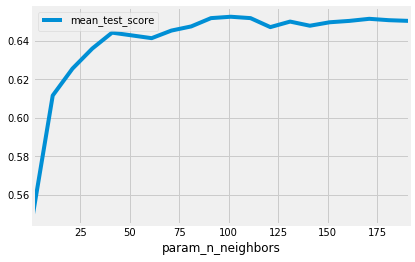

In [28]:
gs_df = pd.DataFrame(knn_gridsearch.cv_results_)
gs_df = gs_df[gs_df['param_metric'] == 'euclidean']
gs_df.plot(x='param_n_neighbors', y='mean_test_score')

<a id='caution'></a>

## A Word of Caution on Grid Searching

---

Sklearn models often have many options/hyperparameters with many different possible values. It may be tempting to search over a wide variety of them. In general, this is not wise.

Remember that **gridsearch searches over all possible combinations of hyperparamters in the paramter dictionary!**

The KNN model class takes a wider range of options during instantiation than we have explored. Imagine that we had this as our parameter dictionary:

```python
parameter_grid = {
    'n_neighbors': range(1, 151),
    'weights': ['uniform', 'distance', custom_function],
    'algorithm': ['ball_tree', 'kd_tree', 'brute', 'auto'],
    'leaf_size': range(1, 152),
    'metric': ['minkowski', 'euclidean'],
    'p': [1, 2]
}
```

**How many different combinations will need to be tested?

| Parameter | Number of Chosen Values |
| --- | --- |
| **n_neighbors** | 150 |
| **weights** | 3 |
| **algorithm** | 4 |
| **leaf_size** | 151 |
| **metric** | 2 |
| **p** | 2 |
| <br>_150 \* 3 \* 4 \* 151 \* 2 \* 2 = n combinations_ <br><br>| _1,087,200_ |

And that is over a million tests *before we even consider the number of cross-validation folds!*

If you're not careful, gridsearching can quickly blow up. A lot of the hyperparameters we put in the dumb example above are either redundant or not useful.

> **It is extremely important to understand what the hyperparameters do and think critically about what ranges are useful and relevant to your model!**


## Another Option:
`from sklearn.model_selection import RandomizedSearchCV`

# Wrapping it all up in a Pipeline
![](../imgs/pipe.png)

## But first: A Scikit-Learn Aside
**DID YOU KNOW?** Scikit-Learn has two types of classes inside? **Estimators** and **transformers**. We've seen several examples of each so far. Here's the rundown of their differences:

### Scikit-Learn Estimators
Estimators are essentially _models_. They fit this format:

```python
model = MyCoolModel(params)
model.fit(X_train, y_train)
y_pred = model.predict(X_test)
```

Estimators have a **fit** and **predict** method.

### Scikit-Learn Transformers
Transformers are not models. They transform your data using similar syntax to estimators. They work like this:

```python
trf = MyCoolTransformer(params)
trf.fit(X_train)
X_transformed = trf.transform(X_train)
```

Instead of predict, they have **fit** and **transform** methods.  In fact, since you fit and transform together so often, they have a shortcut:

```python
trf = MyCoolTransformer(params)
X_transformed = trf.fit_transform(X_train)
```

We've seen a few transformers `StandardScaler()` and `PolynomialFeatures()`. There's also `OneHotEncoder()` for dummy encoding and `LabelEncoder()` for factorizing variables. Later we'll see `PCA()`, which is also a transformer.

### Pipelines
Often, we'll want to apply several transformers to a dataset, and then finally build a model. If you do all of these steps independently, your code when predicting on test data can be messy. It'll also be prone to errors. Luckily, we'll have **pipelines**! Let's code one up.

In [29]:
# Import Pipeline
from sklearn.pipeline import Pipeline

In [30]:
# Build a StandardScaler + kNN pipeline
pipe = Pipeline([
    ('sc', StandardScaler()),
    ('knn', KNeighborsClassifier(n_neighbors=5))
])

# Fit
pipe.fit(X_train, y_train)

/home/tim/.local/lib/python3.6/site-packages/sklearn/preprocessing/data.py:625: DataConversionWarning: Data with input dtype int64, float64 were all converted to float64 by StandardScaler.
  return self.partial_fit(X, y)
/home/tim/.local/lib/python3.6/site-packages/sklearn/base.py:465: DataConversionWarning: Data with input dtype int64, float64 were all converted to float64 by StandardScaler.
  return self.fit(X, y, **fit_params).transform(X)


Pipeline(memory=None,
     steps=[('sc', StandardScaler(copy=True, with_mean=True, with_std=True)), ('knn', KNeighborsClassifier(algorithm='auto', leaf_size=30, metric='minkowski',
           metric_params=None, n_jobs=None, n_neighbors=5, p=2,
           weights='uniform'))])

In [31]:
# Score, predict work!
pipe.score(X_test, y_test)

/home/tim/.local/lib/python3.6/site-packages/sklearn/pipeline.py:511: DataConversionWarning: Data with input dtype int64, float64 were all converted to float64 by StandardScaler.
  Xt = transform.transform(Xt)


0.5786802030456852

In [32]:
# Get params - yes, you can GridSearchCV over these!
# Notice the naming convention of pipe arguments.
pipe.get_params()

{'memory': None,
 'steps': [('sc', StandardScaler(copy=True, with_mean=True, with_std=True)),
  ('knn',
   KNeighborsClassifier(algorithm='auto', leaf_size=30, metric='minkowski',
              metric_params=None, n_jobs=None, n_neighbors=5, p=2,
              weights='uniform'))],
 'sc': StandardScaler(copy=True, with_mean=True, with_std=True),
 'knn': KNeighborsClassifier(algorithm='auto', leaf_size=30, metric='minkowski',
            metric_params=None, n_jobs=None, n_neighbors=5, p=2,
            weights='uniform'),
 'sc__copy': True,
 'sc__with_mean': True,
 'sc__with_std': True,
 'knn__algorithm': 'auto',
 'knn__leaf_size': 30,
 'knn__metric': 'minkowski',
 'knn__metric_params': None,
 'knn__n_jobs': None,
 'knn__n_neighbors': 5,
 'knn__p': 2,
 'knn__weights': 'uniform'}

<a id='practice'></a>

## Practice: Grid Search Regularization Penalties with Logistic Regression

---

Logistic regression models can also apply the Lasso and Ridge penalties. The `LogisticRegression` class takes these regularization-relevant hyperparameters:

| Argument | Description |
| --- | ---|
| **`penalty`** | `'l1'` for Lasso, `'l2'` for Ridge |
| **`solver`** | Must be set to `'liblinear'` for the Lasso penalty to work. |
| **`C`** | The regularization strength. Equivalent to `1./alpha` |

**You should:**
1. Fit and validate the accuracy of a default logistic regression on the basketball data.
- Perform a gridsearch over different regularization strengths and Lasso and Ridge penalties.
- Compare the accuracy on the test set of your optimized logistic regression to the baseline accuracy and the default model.
- Look at the best parameters found. What was chosen? What does this suggest about our data?
- Look at the (non-zero, if Lasso was selected as best) coefficients and associated predictors for your optimized model. What appears to be the most important predictors of winning the game?


In [33]:
from sklearn.linear_model import LogisticRegression

# REMEMBER:
# We already have X_train, X_test unscaled! No need to redefine.

lr = LogisticRegression()
lr.fit(X_train, y_train)

print(lr.score(X_test, y_test))

/home/tim/.local/lib/python3.6/site-packages/sklearn/linear_model/logistic.py:433: FutureWarning: Default solver will be changed to 'lbfgs' in 0.22. Specify a solver to silence this warning.
  FutureWarning)


0.6934010152284263


In [34]:
print(np.mean(y_test))

0.6030456852791878


In [35]:
# Set up the parameters. Looking at C regularization strengths on a log scale.
gs_params = {
    'penalty': ['l1', 'l2'],
    'C': np.logspace(-4, 0, 40)
}

lr_gridsearch = GridSearchCV(
    LogisticRegression(solver='liblinear'),
    gs_params,
    cv=5,
    n_jobs=4,
    verbose=1,
    return_train_score=False
)

In [36]:
lr_gridsearch = lr_gridsearch.fit(X_train, y_train)

Fitting 5 folds for each of 80 candidates, totalling 400 fits


[Parallel(n_jobs=4)]: Using backend LokyBackend with 4 concurrent workers.
[Parallel(n_jobs=4)]: Done 198 tasks      | elapsed:    9.2s
[Parallel(n_jobs=4)]: Done 354 tasks      | elapsed:  1.5min
[Parallel(n_jobs=4)]: Done 400 out of 400 | elapsed:  2.9min finished


In [37]:
# Best score on the training data:
lr_gridsearch.best_score_

0.6629536471433705

In [38]:
# Best parameters on the training data:
lr_gridsearch.best_params_

{'C': 0.00025719138090593444, 'penalty': 'l2'}

In [39]:
# Lasso was chosen: this indicates that maybe unimportant (noise) variables
# is more of an issue in our data than multicollinearity.

In [40]:
# assign the best estimator to a variable:
best_lr = lr_gridsearch.best_estimator_

In [41]:
# Score it on the testing data:
best_lr.score(X_test, y_test)

0.7025380710659899

In [42]:
gs_df = pd.DataFrame(lr_gridsearch.cv_results_)
gs_df = gs_df[gs_df['param_penalty'] == 'l2']

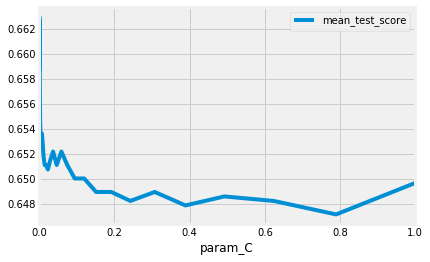

In [43]:
gs_df.plot(x='param_C', y='mean_test_score')